In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

We can test different values later.

In [2]:
NUM_EPOCHS = 30

In [3]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

print(device)

mps


Using CNN with depthwise separable convolution for paramater reduction.

In [4]:
class ConvNet(nn.Module):
  def __init__(self):
        super().__init__()
        # Input 94 x 80 x 1
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=0),  # 92 x 78 x 8
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)       # 46 x 39 x 8
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(8, 8, kernel_size=3, groups=8, padding=0), # 44 x 37 x 8
            nn.Conv2d(8, 12, kernel_size=1, bias=False), # Depthwise separable convolution
            nn.BatchNorm2d(12),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)               # 22 x 18 x 12
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(12, 12, kernel_size=3, groups=12, padding=0), # 20 x 16 x 12
            nn.Conv2d(12, 16, kernel_size=1, bias=False), # Depthwise separable convolution
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)                   # 10 x 8 x 16
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(16, 16, kernel_size=3, groups=16, padding=0), # 8 x 6 x 16
            nn.Conv2d(16, 24, kernel_size=1),
            nn.BatchNorm2d(24),
            nn.ReLU()                                               # 8 x 6 x 24
        )

        # gap might be a bad idea
        # but maybe a smaller adaptive pooling layer will work better
        self.pool = nn.AdaptiveAvgPool2d((2, 2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(24 * 2 * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 10),
        )

  def forward(self, x):
        # Input in (Batch, Channels, Height, Width)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

In [5]:
net = ConvNet().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

In [6]:
total_params = sum(p.numel() for p in net.parameters())
print(f"Total Parameters: {total_params:,}")

Total Parameters: 8,114


We make sure to extract just the green channel.

In [33]:
from transforms_file import extract_green_channel

data_transforms = transforms.Compose([
    transforms.ToTensor(), # We need normalized into 0-1.0
    transforms.Lambda(extract_green_channel)  # Keep only the green channel 
])


train_dataset = datasets.ImageFolder(root="gcp_dataset/train/gcps", transform=data_transforms)
trainloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_dataset = datasets.ImageFolder(root="gcp_dataset/test/gcps", transform=data_transforms)
testloader = DataLoader(
    test_dataset,
    batch_size=32
)

In [8]:
print("Train:", len(train_dataset), "images,", len(trainloader), "batches")
print("Test:", len(test_dataset), "images,", len(testloader), "batches")

Train: 2738 images, 86 batches
Test: 214 images, 7 batches


In [9]:
print("Train classes:", train_dataset.class_to_idx)
print("Test classes:", test_dataset.class_to_idx)
print("Train counts:", torch.bincount(torch.tensor(train_dataset.targets)))
print("Test counts:", torch.bincount(torch.tensor(test_dataset.targets)))

Train classes: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}
Test classes: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}
Train counts: tensor([174, 185, 165, 121, 361, 432, 458, 296, 288, 258])
Test counts: tensor([11, 10,  4, 13, 32, 37, 39, 23, 29, 16])


Testing time on my Mac

In [10]:
import time

def sync_device():
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()

def time_loader(loader, model):
    model.eval()
    sync_device()
    start = time.perf_counter()

    with torch.inference_mode():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            _ = model(X)

    sync_device()
    print(f"{len(loader.dataset)} images: {time.perf_counter() - start:.2f}s")

In [11]:
time_loader(testloader, net)

214 images: 0.88s


In [12]:
time_loader(trainloader, net)

2738 images: 3.27s


In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (bigX, y) in enumerate(dataloader):
        X = bigX[:, :, 74:168, 168:248]
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad(set_to_none=True)

        pred = model(X)
        loss = loss_fn(pred, y)

        loss.backward()
        optimizer.step()

        if batch % 15 == 0:
            loss, current = loss.item(), batch * 32 + len(X)
            print(f"{loss:>7f} [{current:>5d}/{size:>5d}]")

    # Using the scheduler to adjust the learning rate
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    print(f"LR: {current_lr:.6f}")

def test_loop(dataloader, model, loss_fn):
    model.eval()
    total_loss = torch.zeros((), device=device)
    total_correct = torch.zeros((), device=device)
    total = 0

    with torch.inference_mode():
        for bigX, y in dataloader:
            X = bigX[:, :, 74:168, 168:248]
            X = X.to(device)
            y = y.to(device)
            
            logits = model(X)
            total_loss += loss_fn(logits, y) * y.size(0)
            total_correct += (logits.argmax(dim=1) == y).sum()
            total += y.size(0)

    print(
        f"Accuracy: {100 * (total_correct / total).item():.1f}%, "
        f"Loss: {(total_loss / total).item():.4f}\n"
    )

In [15]:
for n in range(NUM_EPOCHS):
    print(f"Epoch {n+1}")
    train_loop(trainloader, net, loss_fn, optimizer)
    test_loop(testloader, net, loss_fn)

print("Done!")

Epoch 1
2.374668 [   32/ 2738]
2.134652 [  512/ 2738]
1.897861 [  992/ 2738]
1.830209 [ 1472/ 2738]
1.761402 [ 1952/ 2738]
1.404958 [ 2432/ 2738]
LR: 0.000997
Accuracy: 65.4%, Loss: 1.1334

Epoch 2
1.282867 [   32/ 2738]
0.906392 [  512/ 2738]
0.755052 [  992/ 2738]
0.832335 [ 1472/ 2738]
0.613350 [ 1952/ 2738]
0.760180 [ 2432/ 2738]
LR: 0.000989
Accuracy: 95.3%, Loss: 0.3426

Epoch 3
0.408263 [   32/ 2738]
0.320307 [  512/ 2738]
0.296966 [  992/ 2738]
0.355103 [ 1472/ 2738]
0.209127 [ 1952/ 2738]
0.313873 [ 2432/ 2738]
LR: 0.000976
Accuracy: 97.2%, Loss: 0.1416

Epoch 4
0.241381 [   32/ 2738]
0.122710 [  512/ 2738]
0.094554 [  992/ 2738]
0.151029 [ 1472/ 2738]
0.152862 [ 1952/ 2738]
0.106388 [ 2432/ 2738]
LR: 0.000957
Accuracy: 97.7%, Loss: 0.1051

Epoch 5
0.099041 [   32/ 2738]
0.126543 [  512/ 2738]
0.120820 [  992/ 2738]
0.068702 [ 1472/ 2738]
0.051220 [ 1952/ 2738]
0.215843 [ 2432/ 2738]
LR: 0.000933
Accuracy: 99.5%, Loss: 0.0583

Epoch 6
0.063480 [   32/ 2738]
0.221693 [  512/ 27

In [16]:
val_dataset = datasets.ImageFolder(root="gcp_dataset/valid/gcps", transform=data_transforms)
valloader = DataLoader(
    val_dataset,
    batch_size=1,
)

In [17]:
test_loop(valloader, net, loss_fn)

Accuracy: 99.7%, Loss: 0.0169



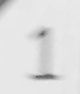

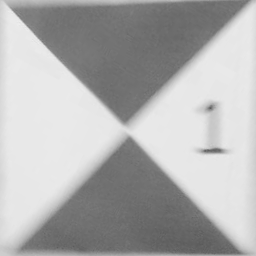

tensor([[ -1.3725,   1.8210,   3.1251,  -1.4364,  -7.5858,  -1.1577,  -6.3792,
          -3.9894,  -6.7583, -10.7081]], device='mps:0')
0.6931796073913574


In [69]:
from torchvision.transforms.functional import to_pil_image
from IPython.display import display

net.eval()
total_loss = torch.zeros((), device=device)
total_correct = torch.zeros((), device=device)
total = 0

with torch.inference_mode():
    for bigX, y in valloader:
        X = bigX[:, :, 74:168, 168:248]
        X = X.to(device)
        y = y.to(device)
        
        logits = net(X)
        total_loss += loss_fn(logits, y) * y.size(0)
        if logits.argmax(dim=1) != y:
            pil_img = to_pil_image(X.squeeze().cpu())
            display(pil_img)
            display(to_pil_image(bigX.squeeze()))
            print(logits)
            print(torch.max(torch.softmax(logits / 1.25, dim=1)).item())
            
            


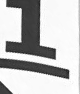

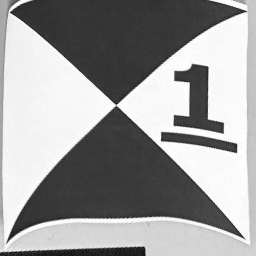

tensor([[ -9.8138,   2.0566,  -3.3350,   2.9948,   1.8135,  -8.4946, -15.5080,
         -11.9100,  -3.6261,  -2.9961]], device='mps:0')
0.5869202613830566


In [66]:
net.eval()
total_loss = torch.zeros((), device=device)
total_correct = torch.zeros((), device=device)
total = 0


with torch.inference_mode():
    for BigX, Y in testloader:
        for i, X in enumerate(BigX):
            bigX = BigX[i]
            X = bigX[:, 74:168, 168:248]
            X = X.unsqueeze(0).to(device)
            y = Y[i].unsqueeze(0).to(device)
            
            logits = net(X)
            total_loss += loss_fn(logits, y) * y.size(0)
            if logits.argmax(dim=1) != y:
                pil_img = to_pil_image(X.squeeze().cpu())
                display(pil_img)
                display(to_pil_image(bigX.squeeze()))
                print(logits)
                print(torch.max(torch.softmax(logits, dim=1)).item())

In [28]:
images, labels = next(iter(valloader))

single_image = images[0].unsqueeze(0)
single_label = labels[0]

single_image = single_image[:, :, 74:168, 168:248]
start = time.perf_counter()
single_image = single_image.to(device)
print(f"Time taken to move single image: {1000 * (time.perf_counter() - start):.2f} ms")


print(single_image.shape)

with torch.no_grad():  
    start = time.perf_counter()
    output = net(single_image)
    print(f"Time taken for single image inference: {1000 * (time.perf_counter() - start):.2f} ms")
    print(output)
    print(single_label.item())

Time taken to move single image: 1.14 ms
torch.Size([1, 1, 94, 80])
Time taken for single image inference: 2.15 ms
tensor([[  8.4431,  -4.0237,  -6.2016, -12.7056,  -3.9555,  -8.0162,  -6.2351,
         -11.2609,   1.9548,  -3.6192]], device='mps:0')
0


In [ ]:
exported_program = torch.export.export(net, args=(torch.randn(1, 1, 94, 80).to(device),))
torch.export.save(exported_program, "team_air_gcp_localization_protoype.pt2")

In [29]:
torch.save(net.state_dict(), "team_air_gcp_localization_protoype.pth")